E-Commerce Customer Segmentation




In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score


In [3]:
from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]

if filename.endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)
else:
    df = pd.read_csv(filename ,encoding="latin1")


Saving Online_Retail.csv to Online_Retail.csv


In [4]:
print(df.head())
print(df.shape)
print(df.columns)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

    InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/10 8:26       2.55     17850.0  United Kingdom  
1  12/1/10 8:26       3.39     17850.0  United Kingdom  
2  12/1/10 8:26       2.75     17850.0  United Kingdom  
3  12/1/10 8:26       3.39     17850.0  United Kingdom  
4  12/1/10 8:26       3.39     17850.0  United Kingdom  
(541909, 8)
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [5]:
print(df.isnull().sum())
print("diplicated :" , df.duplicated().sum())
print(df.dtypes)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
diplicated : 5268
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object


In [6]:
print(df[['Quantity', 'UnitPrice']].describe())

            Quantity      UnitPrice
count  541909.000000  541909.000000
mean        9.552250       4.611114
std       218.081158      96.759853
min    -80995.000000  -11062.060000
25%         1.000000       1.250000
50%         3.000000       2.080000
75%        10.000000       4.130000
max     80995.000000   38970.000000


In [7]:
cancelled = df['InvoiceNo'].astype(str).str.startswith('C')

print("Cancelled invoices:", cancelled.sum())
print("Negative quantities:", (df['Quantity'] < 0).sum())
print("Zero or negative prices:", (df['UnitPrice'] <= 0).sum())

Cancelled invoices: 9288
Negative quantities: 10624
Zero or negative prices: 2517


In [8]:
df = df.dropna()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print(df.head())
print(df.shape)

/tmp/ipykernel_493/4013347423.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])


  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalPrice  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom       15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom       22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
(406829, 9)


In [9]:
df_clean = df.drop_duplicates().copy()

df_clean = df_clean[
    (~df_clean['InvoiceNo'].astype(str).str.startswith('C')) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print(df_clean.shape)

Original rows: 406829
Cleaned rows: 392692
(392692, 9)


In [10]:
print("Current rows:", len(df))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nCancelled invoice with non-negative quantity:",
      (cancelled & (df['Quantity'] >= 0)).sum())

print("\nNegative quantity without cancelled invoice:",
      ((~cancelled) & (df['Quantity'] < 0)).sum())

Current rows: 406829

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64

Duplicate rows: 5225

Cancelled invoice with non-negative quantity: 0

Negative quantity without cancelled invoice: 0


In [11]:
reference_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

print(reference_date)

2011-12-10 12:50:00


In [12]:
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

print(rfm.head())
print(rfm.shape)

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
(4338, 3)


In [13]:
print(rfm.describe())

           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


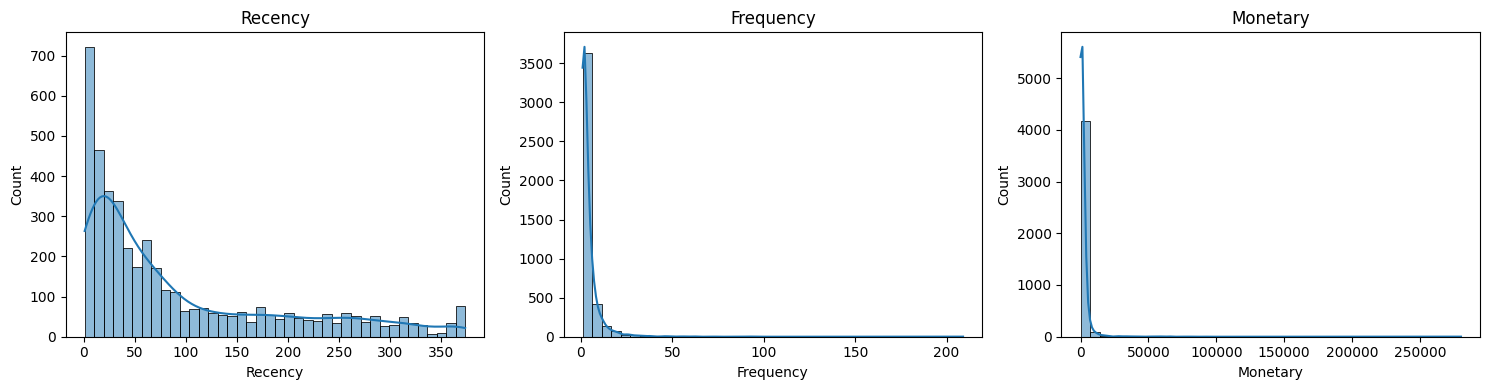

In [14]:
plt.figure(figsize=(15, 4))

for i, col in enumerate(rfm.columns):
    plt.subplot(1, 3, i+1)
    sns.histplot(rfm[col], bins=40, kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

In [15]:
rfm_log = np.log1p(rfm)

print(rfm_log.describe())

           Recency    Frequency     Monetary
count  4338.000000  4338.000000  4338.000000
mean      3.830734     1.345582     6.588562
std       1.340261     0.683104     1.258438
min       0.693147     0.693147     1.558145
25%       2.944439     0.693147     5.728418
50%       3.951244     1.098612     6.506636
75%       4.962845     1.791759     7.415535
max       5.926926     5.347108    12.543284


In [16]:

scaler = StandardScaler()

X = scaler.fit_transform(rfm_log)
print(X.shape)
print("Data scaled successfully!")


(4338, 3)
Data scaled successfully!


In [17]:
print(X.mean(axis=0))
print(X.std(axis=0))

[-9.17252033e-17 -7.20698026e-17 -3.66900813e-16]
[1. 1. 1.]


In [18]:

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["KMeans"] = kmeans.fit_predict(X)

print(rfm["KMeans"].value_counts())

print("Silhouette Score:",
      round(silhouette_score(X, rfm["KMeans"]), 3))


KMeans
1    1622
3    1166
2     837
0     713
Name: count, dtype: int64
Silhouette Score: 0.338


In [19]:
cluster_profile = rfm.groupby('KMeans')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

print(cluster_profile.round(2))

        Recency  Frequency  Monetary
KMeans                              
0         12.17      13.75   8088.02
1        181.51       1.32    341.00
2         17.70       2.19    557.32
3         71.64       4.08   1801.78


In [31]:
for cluster in sorted(rfm["KMeans"].unique()):

    data = rfm[rfm["KMeans"] == cluster]

    recency = data["Recency"].mean()
    frequency = data["Frequency"].mean()
    monetary = data["Monetary"].mean()

    if frequency > rfm["Frequency"].median() and monetary > rfm["Monetary"].median():
        print("Cluster", cluster, "- Loyal Customers")
        print("Action: Give loyalty rewards and special offers")

    elif recency > rfm["Recency"].median():
        print("Cluster", cluster, "- Inactive Customers")
        print("Action: Send re-engagement offers")

    else:
        print("Cluster", cluster, "- Regular Customers")
        print("Action: Encourage repeat purchases")

    print()

Cluster 0 - Loyal Customers
Action: Give loyalty rewards and special offers

Cluster 1 - Inactive Customers
Action: Send re-engagement offers

Cluster 2 - Regular Customers
Action: Encourage repeat purchases

Cluster 3 - Loyal Customers
Action: Give loyalty rewards and special offers



In [20]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print("Original shape:", X.shape)
print("Reduced shape:", X_pca.shape)

print("Explained variance:",
      pca.explained_variance_ratio_)

print("Total variance:",
      sum(pca.explained_variance_ratio_))

Original shape: (4338, 3)
Reduced shape: (4338, 2)
Explained variance: [0.75078634 0.18786648]
Total variance: 0.9386528181989533


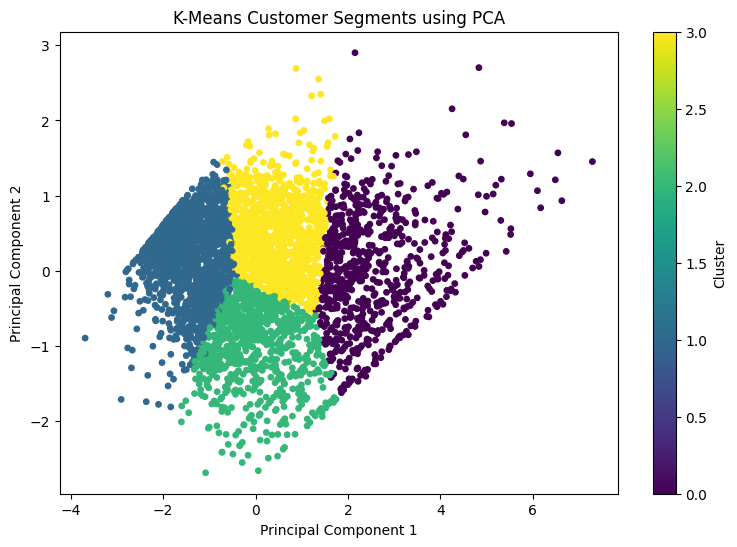

In [21]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm['KMeans'],
    cmap='viridis',
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Segments using PCA")
plt.colorbar(label="Cluster")
plt.show()

In [22]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X)

print(X_tsne.shape)

(4338, 2)


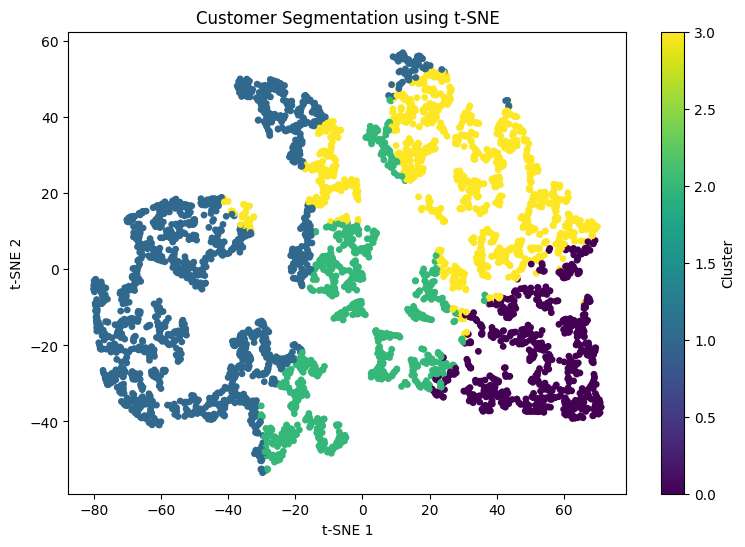

In [23]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=rfm['KMeans'],
    cmap='viridis',
    s=15
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Customer Segmentation using t-SNE")
plt.colorbar(label="Cluster")
plt.show()

In [25]:

dbscan = DBSCAN(eps=0.5, min_samples=5)

db_labels = dbscan.fit_predict(X)

rfm['DBSCAN'] = db_labels

print(rfm['DBSCAN'].value_counts())


DBSCAN
 0    2791
 1    1485
-1      62
Name: count, dtype: int64


In [26]:
mask = db_labels != -1

if len(set(db_labels[mask])) >= 2:
    score = silhouette_score(X[mask], db_labels[mask])
    print("DBSCAN Silhouette Score:", round(score, 3))
else:
    print("Silhouette Score cannot be calculated.")

DBSCAN Silhouette Score: 0.293


In [27]:
dbscan_profile = rfm.groupby('DBSCAN')[['Recency', 'Frequency', 'Monetary']].mean()
print(dbscan_profile)

           Recency  Frequency      Monetary
DBSCAN                                     
-1       54.564516  33.209677  43840.678226
 0       59.151200   5.370118   2021.950123
 1      156.868013   1.000000    354.090270


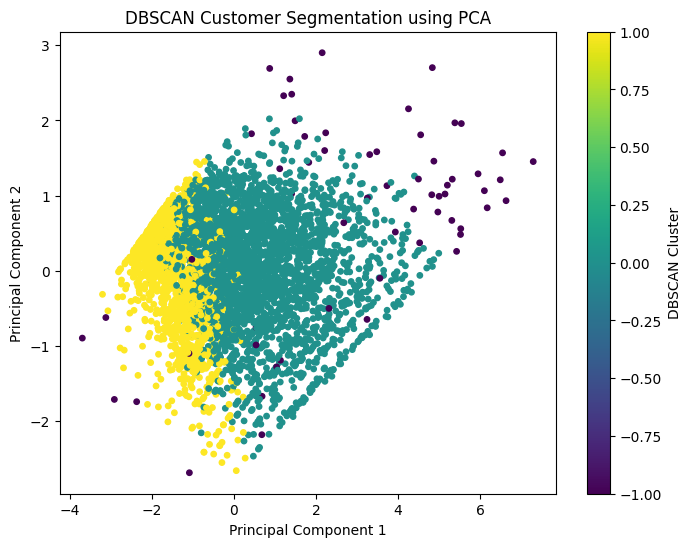

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm['DBSCAN'],
    cmap='viridis',
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Customer Segmentation using PCA")
plt.colorbar(label="DBSCAN Cluster")
plt.show()

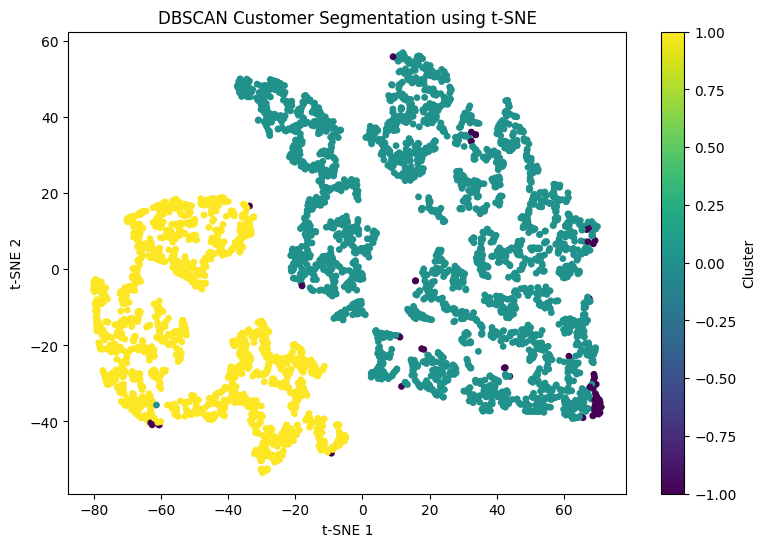

In [29]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=rfm['DBSCAN'],
    cmap='viridis',
    s=15
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("DBSCAN Customer Segmentation using t-SNE")
plt.colorbar(label="Cluster")
plt.show()

In [32]:
noise_count = (db_labels == -1).sum()

print("Noise customers:", noise_count)
print("Noise percentage:", round(noise_count / len(db_labels) * 100, 2), "%")

Noise customers: 62
Noise percentage: 1.43 %


In [30]:

rfm.to_csv("customer_segmentation_results.csv")

files.download("customer_segmentation_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>